In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import torch
import matplotlib.pyplot as plt

# Prepare ice flux (q) observation tensor

Create a tensor with columns [x_norm, y_norm, flux_x_scaled, flux_y_scaled]

In [2]:
# import region bounds
from regions import ROSS_ISLAND_BOUNDS

# assign region bounds
x_min = ROSS_ISLAND_BOUNDS["x_min"]
x_max = ROSS_ISLAND_BOUNDS["x_max"]
y_min = ROSS_ISLAND_BOUNDS["y_min"]
y_max = ROSS_ISLAND_BOUNDS["y_max"]

## Load cleaned thickness point data

In [3]:
# Load thickness points
# NOTE: Outliers are removed from this file.
thickness = pd.read_csv("data/bedmap123_ross_island_cleaned_240k.csv")
thickness.describe()

,lon,lat,x,y,s,t,b,t_fa,x_norm,y_norm
count,239322.000000,239322.000000,239322.000000,2.393220e+05,239322.000000,239322.000000,239322.000000,239322.000000,239322.000000,239322.000000
mean,169.766256,-77.950201,233135.204297,-1.292334e+06,-18.543475,209.883613,-228.278382,199.883613,0.833135,0.107666
std,1.876531,0.288199,41743.752795,3.335664e+04,27.739584,91.907906,84.777305,91.907906,0.041744,0.033357
min,164.456675,-78.702596,160001.173583,-1.360492e+06,-9999.000000,-0.000000,-9999.000000,-10.000000,0.760001,0.039508
25%,168.192624,-78.074054,197657.364155,-1.312525e+06,-24.090000,154.410000,-297.795194,144.410000,0.797657,0.087475
50%,169.806980,-77.937494,230629.762263,-1.290262e+06,-17.387521,209.444147,-227.800000,199.444147,0.830630,0.109738
75%,171.562567,-77.772116,267410.316563,-1.274692e+06,-8.530000,288.610000,-176.410000,278.610000,0.867410,0.125308
max,173.270610,-77.390900,344755.398707,-1.220004e+06,1018.092794,478.949749,539.143045,468.949749,0.944755,0.179996


## Load raw ice velocity data

- 120 m nominal resolution
- interpolate at point locations

In [3]:
# Load ice velocity data (raw)
# TODO define local path to ice velocity data
ice_vel = xr.load_dataset("/Users/kim.bente/DATA/ice_velocity/ITS_LIVE_velocity_120m_RGI19A_0000_V02.1.nc")

: 

In [ ]:
# Load ice velocity data (raw)
# TODO define local path to ice velocity data
ice_vel = xr.load_dataset("/Users/kim.bente/DATA/ice_velocity/ITS_LIVE_velocity_120m_RGI19A_0000_V02.1.nc")

# crop
velocity = ice_vel.sel(
    x = slice(x_min, x_max), 
    y = slice(y_max, y_min))

In [ ]:
# Interpolate
vel_at_points = velocity[["VX", "VY"]].interp(
    x = ("points", thickness["x"].values),
    y = ("points", thickness["y"].values),
    method = "linear",
)

# Add to dataset
thickness["VX"] = vel_at_points["VX"].values
thickness["VY"] = vel_at_points["VY"].values

# 240k
print(thickness.shape)

(239322, 14)


In [6]:
# Multiply velocity components by thickness (t_fa) to get flux components
thickness["VX_flux"] = thickness["VX"] * thickness["t_fa"]
thickness["VY_flux"] = thickness["VY"] * thickness["t_fa"]

# If you also want total flux magnitude
thickness["flux_mag"] = np.hypot(thickness["VX_flux"], thickness["VY_flux"])

# Optionally drop rows with NaNs if you want a clean dataset
# Check for NaNs
print(thickness[["VX_flux", "VY_flux", "flux_mag"]].isna().sum())

# Remove so that 240k points remain
thickness = thickness.dropna(subset = ["VX_flux", "VY_flux", "flux_mag"])
print(thickness.shape)

VX_flux     4378
VY_flux     4378
flux_mag    4378
dtype: int64
(234944, 17)


## Load MODIS MOA for visualisation backrgound

In [7]:
modis_ross = torch.load("data/modis/moa125_2014_hp1_v01_ross_with_grid_no_ocean.pt", weights_only = False)

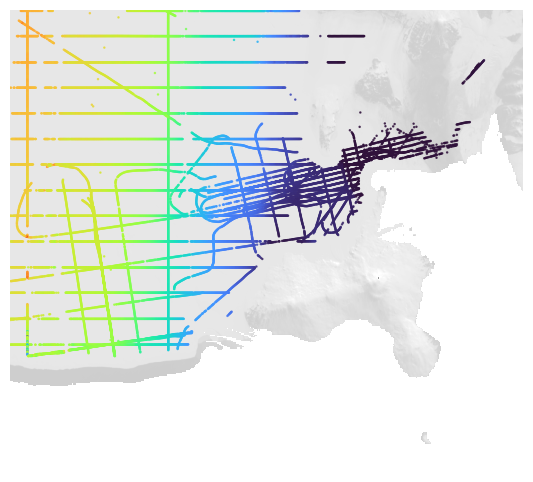

In [8]:
# Use same subsample rate as the ice thickness visualisations
SUBSAMPLE_RATE = 10

fig, ax = plt.subplots(figsize = (8, 6))

# 1) MODIS as background (draw first)
ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[2],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

# 2) SMB on top (draw second)
ax.scatter(
    thickness["x"][::SUBSAMPLE_RATE], 
    thickness["y"][::SUBSAMPLE_RATE], 
    c = thickness["flux_mag"][::SUBSAMPLE_RATE], 
    s = 0.6, 
    alpha = 0.8, 
    cmap = "turbo",
    vmin = 0,
    # 400 k worked well
    vmax = 400_000 
    )

ax.set_aspect("equal")
ax.set_axis_off()

# crop
ax.set_ylim(y_min, y_max)
ax.set_xlim(x_min, x_max)

fig.savefig("figures/ice_flux_ross_island.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

## cmap

In [11]:
cmap = "turbo"
dpi = 300

# 1 x N gradient
grad = np.linspace(0, 1, 2048)[None, :]

fig = plt.figure(figsize = (6, 0.6), dpi = dpi)
ax = fig.add_axes([0, 0, 1, 1]) 
ax.imshow(grad, aspect = "auto", cmap = cmap)
ax.set_axis_off()

fig.savefig("figures/cmap/turbo_bar.png", dpi = dpi, transparent = True, bbox_inches = "tight", pad_inches = 0)
plt.close(fig)

# Visualise sparse raw flux vectors - region

(for presentation)

In [13]:
thickness

# 50 x 50 km zoomed in region
x_min_zoom = 200_000
x_max_zoom = 250_000

y_min_zoom = - 1_360_000
y_max_zoom = - 1_310_000

thickness_zoom = thickness[
    (thickness["x"] >= x_min_zoom) &
    (thickness["x"] <= x_max_zoom) &
    (thickness["y"] >= y_min_zoom) &
    (thickness["y"] <= y_max_zoom)
]

thickness_zoom

,lon,lat,x,y,s,t,b,b_inferred,source,t_fa,x_norm,y_norm,VX,VY,VX_flux,VY_flux,flux_mag
62,171.436700,-77.683500,200003.138625,-1.328213e+06,45.00,271.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,261.00,0.800003,0.071787,159.760460,-747.219778,41697.480094,-195024.362132,199432.148038
63,171.439500,-77.662900,200275.129348,-1.330461e+06,45.00,268.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,258.00,0.800275,0.069539,163.800800,-747.590113,42260.606436,-192878.249072,197453.735902
64,171.443800,-77.642300,200512.023123,-1.332714e+06,44.00,266.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,256.00,0.800512,0.067286,161.666571,-746.095930,41386.642290,-191000.558019,195433.025161
65,171.446600,-77.621600,200785.175936,-1.334973e+06,44.00,264.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,254.00,0.800785,0.065027,165.670339,-747.652939,42080.266216,-189903.846505,194510.204673
66,171.456300,-77.599700,200916.669530,-1.337386e+06,44.00,259.00,0.00,False,BEDMAP1_1966-2000_AIR_BM1.csv,249.00,0.800917,0.062614,175.355232,-746.867352,43663.452668,-185969.970733,191027.032415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
239153,171.567977,-77.443587,200825.331451,-1.354747e+06,-9.90,244.31,-254.21,False,UTIG_2010_ICECAP_AIR_BM3.csv,234.31,0.800825,0.045253,214.516897,-744.109095,50263.454023,-174352.201992,181452.762861
239154,171.567976,-77.443384,200828.626940,-1.354769e+06,-10.67,243.83,-254.49,False,UTIG_2010_ICECAP_AIR_BM3.csv,233.83,0.800829,0.045231,214.574605,-744.083703,50173.979966,-173989.092312,181079.078055
239155,171.567975,-77.443177,200831.986901,-1.354791e+06,-11.05,243.56,-254.61,False,UTIG_2010_ICECAP_AIR_BM3.csv,233.56,0.800832,0.045209,214.634579,-744.057254,50130.052235,-173782.012304,180867.935073
239156,171.567974,-77.442973,200835.298512,-1.354813e+06,-11.32,243.44,-254.77,False,UTIG_2010_ICECAP_AIR_BM3.csv,233.44,0.800835,0.045187,214.694802,-744.030637,50118.354546,-173686.511857,180772.934543


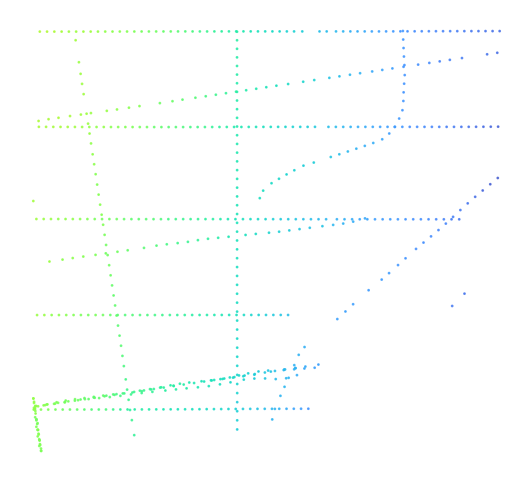

In [19]:
SUBSAMPLE_RATE = 50

fig, ax = plt.subplots(figsize = (8, 6))

# 2) SMB on top (draw second)
ax.scatter(
    thickness_zoom["x"][::SUBSAMPLE_RATE], 
    thickness_zoom["y"][::SUBSAMPLE_RATE], 
    c = thickness_zoom["flux_mag"][::SUBSAMPLE_RATE], 
    s = 1.0, 
    alpha = 0.8, 
    cmap = "turbo",
    vmin = 0,
    # 400 k worked well
    vmax = 400_000 
    )

ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig("figures/ice_flux_ross_island_zoom.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

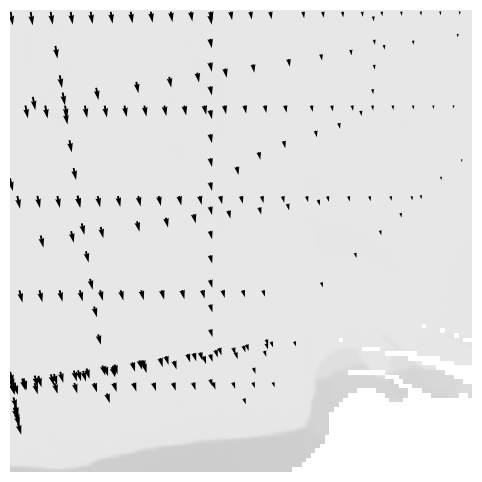

In [20]:
SUBSAMPLE_RATE = 140

fig, ax = plt.subplots(figsize = (8, 6))

ax.pcolormesh(
    modis_ross[0],
    modis_ross[1], 
    modis_ross[2],
    cmap = "gray",
    # softer greys
    vmin = -30_000, 
    vmax = 30_000,
    # as less saturated background
    alpha = 0.4,
    zorder = 0,
)

ax.quiver(
    thickness_zoom["x"][::SUBSAMPLE_RATE], 
    thickness_zoom["y"][::SUBSAMPLE_RATE], 
    thickness_zoom["VX_flux"][::SUBSAMPLE_RATE], 
    thickness_zoom["VY_flux"][::SUBSAMPLE_RATE],
    scale = 7_000_000.0,
    # width = 0.005,
)

ax.set_ylim(y_min_zoom, y_max_zoom)
ax.set_xlim(x_min_zoom, x_max_zoom)

ax.set_aspect("equal")
ax.set_axis_off()
fig.savefig("figures/ice_flux_ross_island_zoom.png", dpi = 300, bbox_inches = "tight", pad_inches = 0)
plt.show()

## Histogram of flux magnitude

Observation: most values are under 400k.
We thus normalise by 100k.

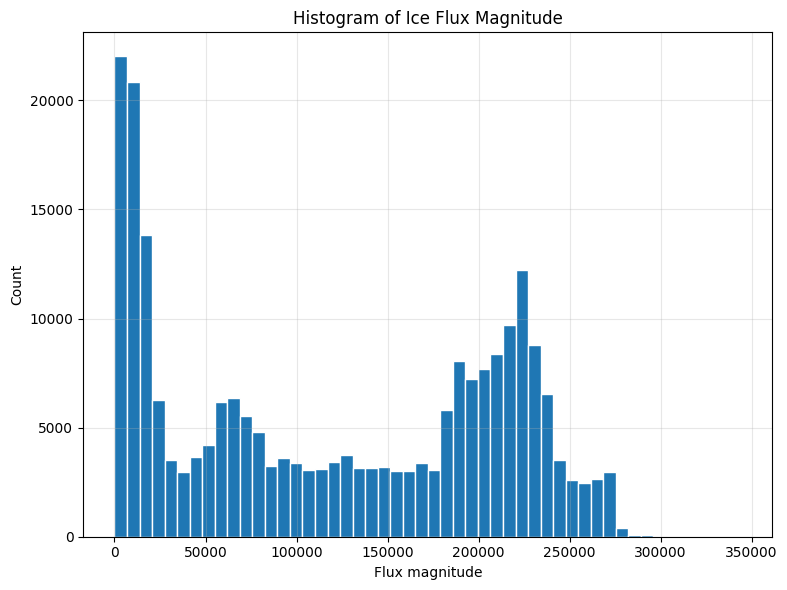

In [21]:
plt.figure(figsize = (8, 6))
plt.hist(thickness["flux_mag"], bins = 50, edgecolor=  "white")
plt.xlabel("Flux magnitude")
plt.ylabel("Count")
plt.title("Histogram of Ice Flux Magnitude")
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.show()

## Affirm normalisation scalar

In [24]:
# Print variance after normalisation
print(np.var(thickness["VX_flux"] / 100_000))
print(np.var(thickness["VY_flux"] / 100_000))

0.02471507363711703
0.8295131567071812


## Normalise

Example: 425 meter ice * 438 meter per year (mean)  
425 * 438 = 186_150 m^2/yr

In [25]:
# Normalize into [0, 1]
thickness["x_norm"] = (thickness["x"] - x_min) / (x_max - x_min)
thickness["y_norm"] = (thickness["y"] - y_min) / (y_max - y_min)

# Build tensor with x_norm, y_norm, scaled flux
flux_tensor = torch.tensor(
    np.stack([
        thickness["x_norm"].values,
        thickness["y_norm"].values,
        thickness["VX_flux"].values / 100_000,
        thickness["VY_flux"].values / 100_000,
    ], axis = 1),
    dtype = torch.float32
)

print(flux_tensor.shape)
# preview first rows
print(flux_tensor[:5])

torch.Size([234944, 4])
tensor([[ 0.2823,  0.8636,  0.0390, -2.0019],
        [ 0.4140,  0.7178,  0.1032, -1.0579],
        [ 0.4460,  0.6884,  0.0788, -0.6993],
        [ 0.4846,  0.6565,  0.0680, -0.4635],
        [ 0.5229,  0.6382,  0.0696, -0.1831]])


### Histogram after normalisation

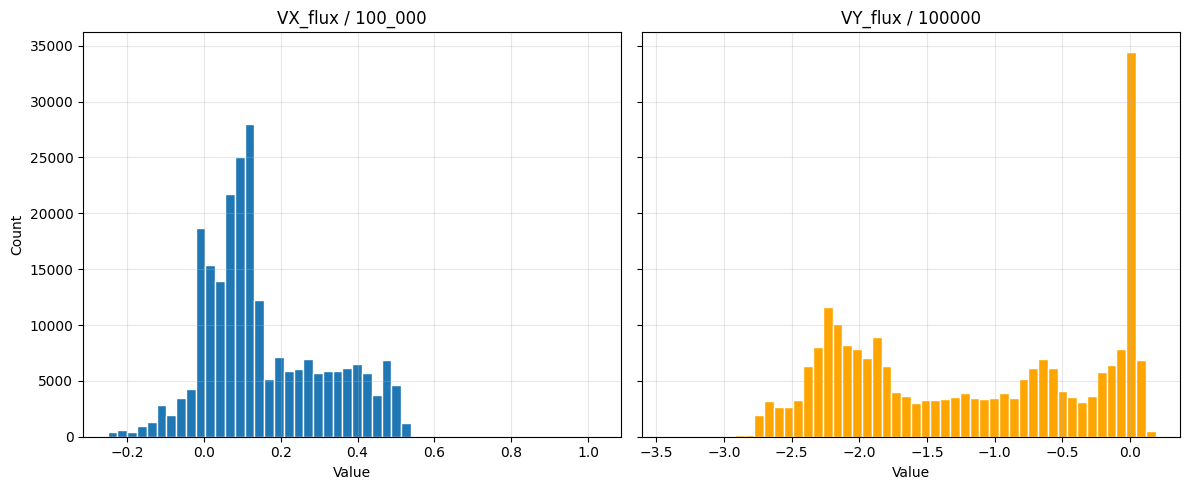

In [26]:
# Extract the last two columns
vx_flux_scaled = flux_tensor[:, 2].numpy()
vy_flux_scaled = flux_tensor[:, 3].numpy()

# Plot histograms
fig, axes = plt.subplots(1, 2, figsize = (12, 5), sharey = True)

axes[0].hist(vx_flux_scaled, bins = 50, edgecolor = "white")
axes[0].set_title("VX_flux / 100_000")
axes[0].set_xlabel("Value")
axes[0].set_ylabel("Count")
axes[0].grid(alpha = 0.3)

axes[1].hist(vy_flux_scaled, bins = 50, edgecolor = "white", color = "orange")
axes[1].set_title("VY_flux / 100000")
axes[1].set_xlabel("Value")
axes[1].grid(alpha = 0.3)

plt.tight_layout()
plt.show()

# Export tensor with all flux observations

In [27]:
torch.save(flux_tensor, "data/flux_tensor.pt")